In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error

In [ ]:
df = pd.read_csv('/content/battery_cycle_level_dataset_CLEAN_FINAL.csv')

# Since your dataset already has 'soh' and 'rul' columns, we don't need to recalculate them.
# We will just map them to the names the rest of the code expects for clarity.
df['SoH'] = df['soh']
df['RUL'] = df['rul']

# Separate train and test sets
train_df = df[df['battery_id'] != 'B0018'].copy()
test_df = df[df['battery_id'] == 'B0018'].copy()

features = ['cycle', 'voltage', 'temperature', 'capacity']

In [ ]:
feature_scaler = MinMaxScaler()
train_df[features] = feature_scaler.fit_transform(train_df[features])
test_df[features] = feature_scaler.transform(test_df[features])

target_scaler_soh = MinMaxScaler()
target_scaler_rul = MinMaxScaler()

train_df['SoH_scaled'] = target_scaler_soh.fit_transform(train_df[['SoH']])
train_df['RUL_scaled'] = target_scaler_rul.fit_transform(train_df[['RUL']])

test_df['SoH_scaled'] = target_scaler_soh.transform(test_df[['SoH']])
test_df['RUL_scaled'] = target_scaler_rul.transform(test_df[['RUL']])

In [ ]:
WINDOW_SIZE = 10

def create_sequences_per_battery(data, feature_cols, soh_col, rul_col, window_size):
    X, y_soh, y_rul, cycles = [], [], [], []

    # NEW: Group by battery_id so windows do NOT cross between different batteries
    for battery_id, group in data.groupby('battery_id'):
        # Only process batteries that have more cycles than the window size
        if len(group) <= window_size:
            continue

        for i in range(len(group) - window_size):
            X.append(group[feature_cols].iloc[i : i + window_size].values)
            y_soh.append(group[soh_col].iloc[i + window_size])
            y_rul.append(group[rul_col].iloc[i + window_size])
            cycles.append(group['cycle'].iloc[i + window_size])

    return np.array(X), np.array(y_soh), np.array(y_rul), np.array(cycles)

X_train, y_train_soh, y_train_rul, _ = create_sequences_per_battery(
    train_df, features, 'SoH_scaled', 'RUL_scaled', WINDOW_SIZE
)

X_test, y_test_soh, y_test_rul, test_cycles_scaled = create_sequences_per_battery(
    test_df, features, 'SoH_scaled', 'RUL_scaled', WINDOW_SIZE
)

# Recover actual cycle numbers for the test plot
dummy_unscale = np.zeros((len(test_cycles_scaled), len(features)))
dummy_unscale[:, 0] = test_cycles_scaled
test_cycles = feature_scaler.inverse_transform(dummy_unscale)[:, 0]

In [ ]:
input_layer = Input(shape=(WINDOW_SIZE, len(features)))

# Spatial extraction
x = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same')(input_layer)
x = MaxPooling1D(pool_size=2)(x)
x = Dropout(0.2)(x)

# Temporal mapping
x = LSTM(50, return_sequences=False, activation='tanh')(x)
x = Dropout(0.2)(x)

# Shared Dense
shared_dense = Dense(32, activation='relu')(x)

# Multi-Output Heads
out_soh = Dense(1, name='soh_output')(shared_dense)
out_rul = Dense(1, name='rul_output')(shared_dense)

model = Model(inputs=input_layer, outputs=[out_soh, out_rul])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={'soh_output': 'mse', 'rul_output': 'huber'},

    # FIX: Specify the metric for each output explicitly using a dictionary
    metrics={'soh_output': 'mae', 'rul_output': 'mae'}
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True
)

history = model.fit(
    X_train,
    {'soh_output': y_train_soh, 'rul_output': y_train_rul},
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - loss: 0.1272 - rul_output_loss: 0.0417 - rul_output_mae: 0.2371 - soh_output_loss: 0.0837 - soh_output_mae: 0.2275 - val_loss: 0.0688 - val_rul_output_loss: 0.0075 - val_rul_output_mae: 0.1006 - val_soh_output_loss: 0.0750 - val_soh_output_mae: 0.1864
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0471 - rul_output_loss: 0.0268 - rul_output_mae: 0.1799 - soh_output_loss: 0.0204 - soh_output_mae: 0.1125 - val_loss: 0.0665 - val_rul_output_loss: 0.0095 - val_rul_output_mae: 0.1234 - val_soh_output_loss: 0.0720 - val_soh_output_mae: 0.1633
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0393 - rul_output_loss: 0.0226 - rul_output_mae: 0.1674 - soh_output_loss: 0.0162 - soh_output_mae: 0.0992 - val_loss: 0.0681 - val_rul_output_loss: 0.0134 - val_rul_output_mae: 0.1507 - val_soh_output_loss: 0.0676 - val_soh_output_mae: 0.1775
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0381 - rul_output_lo

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step

--- Evaluation on Unseen Test Battery: B0018 (CNN-LSTM) ---
SoH Mean Absolute Error: 0.0150
RUL Mean Absolute Error: 21.53 cycles



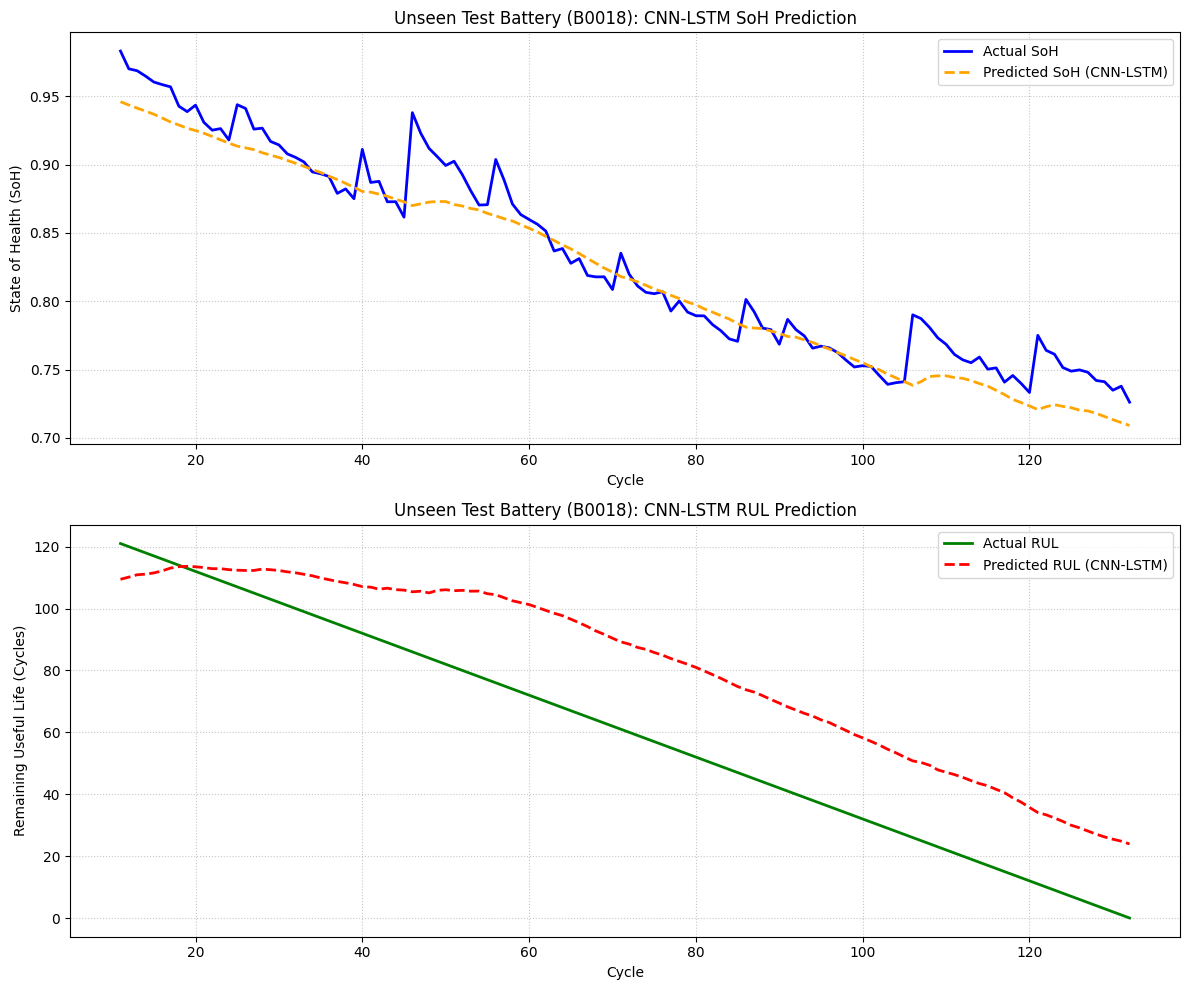

In [ ]:
raw_predictions = model.predict(X_test)

pred_soh = target_scaler_soh.inverse_transform(raw_predictions[0])
pred_rul = target_scaler_rul.inverse_transform(raw_predictions[1])

actual_soh = target_scaler_soh.inverse_transform(y_test_soh.reshape(-1, 1))
actual_rul = target_scaler_rul.inverse_transform(y_test_rul.reshape(-1, 1))

mae_soh = mean_absolute_error(actual_soh, pred_soh)
mae_rul = mean_absolute_error(actual_rul, pred_rul)

print("\n--- Evaluation on Unseen Test Battery: B0018 (CNN-LSTM) ---")
print(f"SoH Mean Absolute Error: {mae_soh:.4f}")
print(f"RUL Mean Absolute Error: {mae_rul:.2f} cycles\n")

# Plotting
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

ax1.plot(test_cycles, actual_soh, label='Actual SoH', color='blue', linewidth=2)
ax1.plot(test_cycles, pred_soh, label='Predicted SoH (CNN-LSTM)', color='orange', linestyle='--', linewidth=2)
ax1.set_title('Unseen Test Battery (B0018): CNN-LSTM SoH Prediction')
ax1.set_xlabel('Cycle')
ax1.set_ylabel('State of Health (SoH)')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.7)

ax2.plot(test_cycles, actual_rul, label='Actual RUL', color='green', linewidth=2)
ax2.plot(test_cycles, pred_rul, label='Predicted RUL (CNN-LSTM)', color='red', linestyle='--', linewidth=2)
ax2.set_title('Unseen Test Battery (B0018): CNN-LSTM RUL Prediction')
ax2.set_xlabel('Cycle')
ax2.set_ylabel('Remaining Useful Life (Cycles)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy.stats import pearsonr, spearmanr
from sklearn.preprocessing import MinMaxScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, median_absolute_error, max_error)

N_SEEDS = 3

y_true_soh, y_hat_soh = actual_soh.ravel(), pred_soh.ravel()
y_true_rul, y_hat_rul = actual_rul.ravel(), pred_rul.ravel()

# ------------------------------------------------------------
# 1. Full metrics (accuracy + correlation)
# ------------------------------------------------------------
def full_metrics(y_true, y_pred, name):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-8, None))) * 100
    pear, _  = pearsonr(y_true, y_pred)
    spear, _ = spearmanr(y_true, y_pred)
    return pd.Series({
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MedAE': median_absolute_error(y_true, y_pred),
        'MaxError': max_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE_%': mape,
        'Pearson_r': pear,
        'Spearman_rho': spear,
        'Bias(mean error)': np.mean(y_pred - y_true),
    }, name=name)

results = pd.DataFrame([full_metrics(y_true_soh, y_hat_soh, 'SoH'),
                        full_metrics(y_true_rul, y_hat_rul, 'RUL')])
print("=== CNN-LSTM test metrics on B0018 ===")
print(results.round(4).T)

=== CNN-LSTM test metrics on B0018 ===
                     SoH           RUL
MAE               0.0150  2.153150e+01
RMSE              0.0202  2.312510e+01
MedAE             0.0112  2.530650e+01
MaxError          0.0681  2.968950e+01
R2                0.9244  5.688000e-01
MAPE_%            1.8012  1.960237e+09
Pearson_r         0.9733  9.677000e-01
Spearman_rho      0.9638  9.913000e-01
Bias(mean error) -0.0111  2.074370e+01


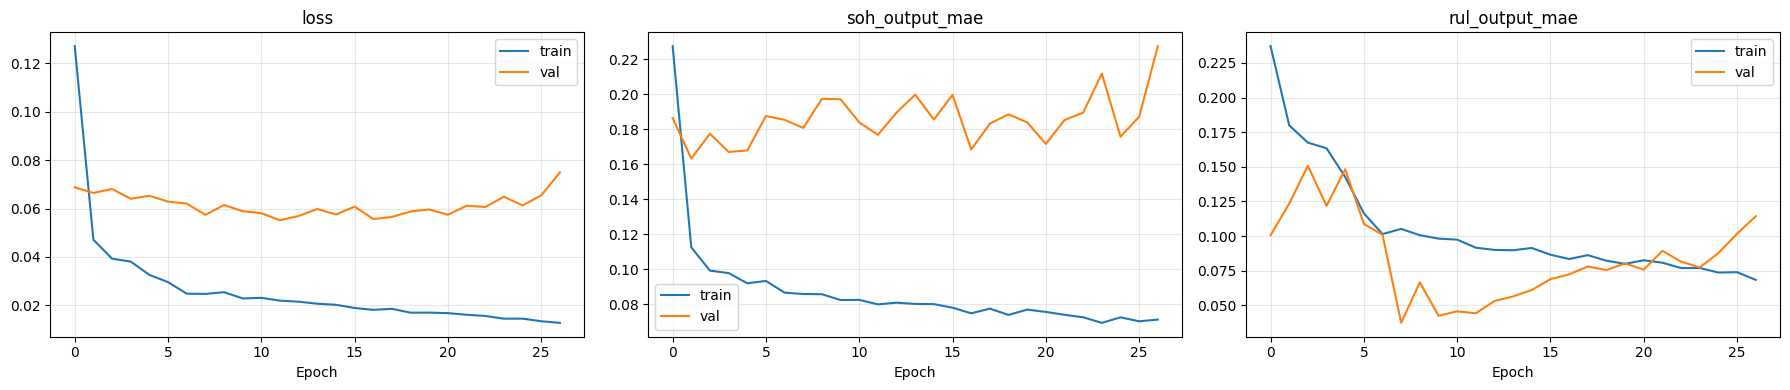

Best epoch (min val_loss): 12 / 27


In [ ]:
# ------------------------------------------------------------
# 2. Training curves (overfitting check)
# ------------------------------------------------------------
h = history.history
pairs = [('loss', 'val_loss'),
         ('soh_output_mae', 'val_soh_output_mae'),
         ('rul_output_mae', 'val_rul_output_mae')]
pairs = [(a, b) for a, b in pairs if a in h and b in h]
fig, axes = plt.subplots(1, len(pairs), figsize=(6 * len(pairs), 4))
axes = np.atleast_1d(axes)
for ax, (tr_k, va_k) in zip(axes, pairs):
    ax.plot(h[tr_k], label='train'); ax.plot(h[va_k], label='val')
    ax.set_title(tr_k); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Best epoch (min val_loss): {int(np.argmin(h['val_loss'])) + 1} / {len(h['val_loss'])}")

In [ ]:
# ------------------------------------------------------------
# 3. Baseline comparison (same windows, flattened)
# ------------------------------------------------------------
Xtr_flat = X_train.reshape(len(X_train), -1)
Xte_flat = X_test.reshape(len(X_test), -1)
Ytr = np.column_stack([y_train_soh, y_train_rul])   # scaled targets

def unscale(p):
    s = target_scaler_soh.inverse_transform(p[:, [0]]).ravel()
    r = target_scaler_rul.inverse_transform(p[:, [1]]).ravel()
    return s, r

baselines = {
    'Mean predictor': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Random Forest (flat window)': RandomForestRegressor(
        n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
}
rows = []
for name, m in baselines.items():
    m.fit(Xtr_flat, Ytr)
    s, r = unscale(m.predict(Xte_flat))
    rows.append({'Model': name,
                 'SoH_MAE': mean_absolute_error(y_true_soh, s), 'SoH_R2': r2_score(y_true_soh, s),
                 'RUL_MAE': mean_absolute_error(y_true_rul, r), 'RUL_R2': r2_score(y_true_rul, r)})
rows.append({'Model': 'CNN-LSTM',
             'SoH_MAE': mean_absolute_error(y_true_soh, y_hat_soh), 'SoH_R2': r2_score(y_true_soh, y_hat_soh),
             'RUL_MAE': mean_absolute_error(y_true_rul, y_hat_rul), 'RUL_R2': r2_score(y_true_rul, y_hat_rul)})
print("\n=== Baseline comparison ===")
print(pd.DataFrame(rows).round(4).to_string(index=False))


=== Baseline comparison ===
                      Model  SoH_MAE  SoH_R2  RUL_MAE  RUL_R2
             Mean predictor   0.0655 -0.0087  31.0913 -0.0584
          Linear Regression   0.0129  0.9552  12.9808  0.7997
Random Forest (flat window)   0.0225  0.8495   7.4077  0.9227
                   CNN-LSTM   0.0150  0.9244  21.5315  0.5688


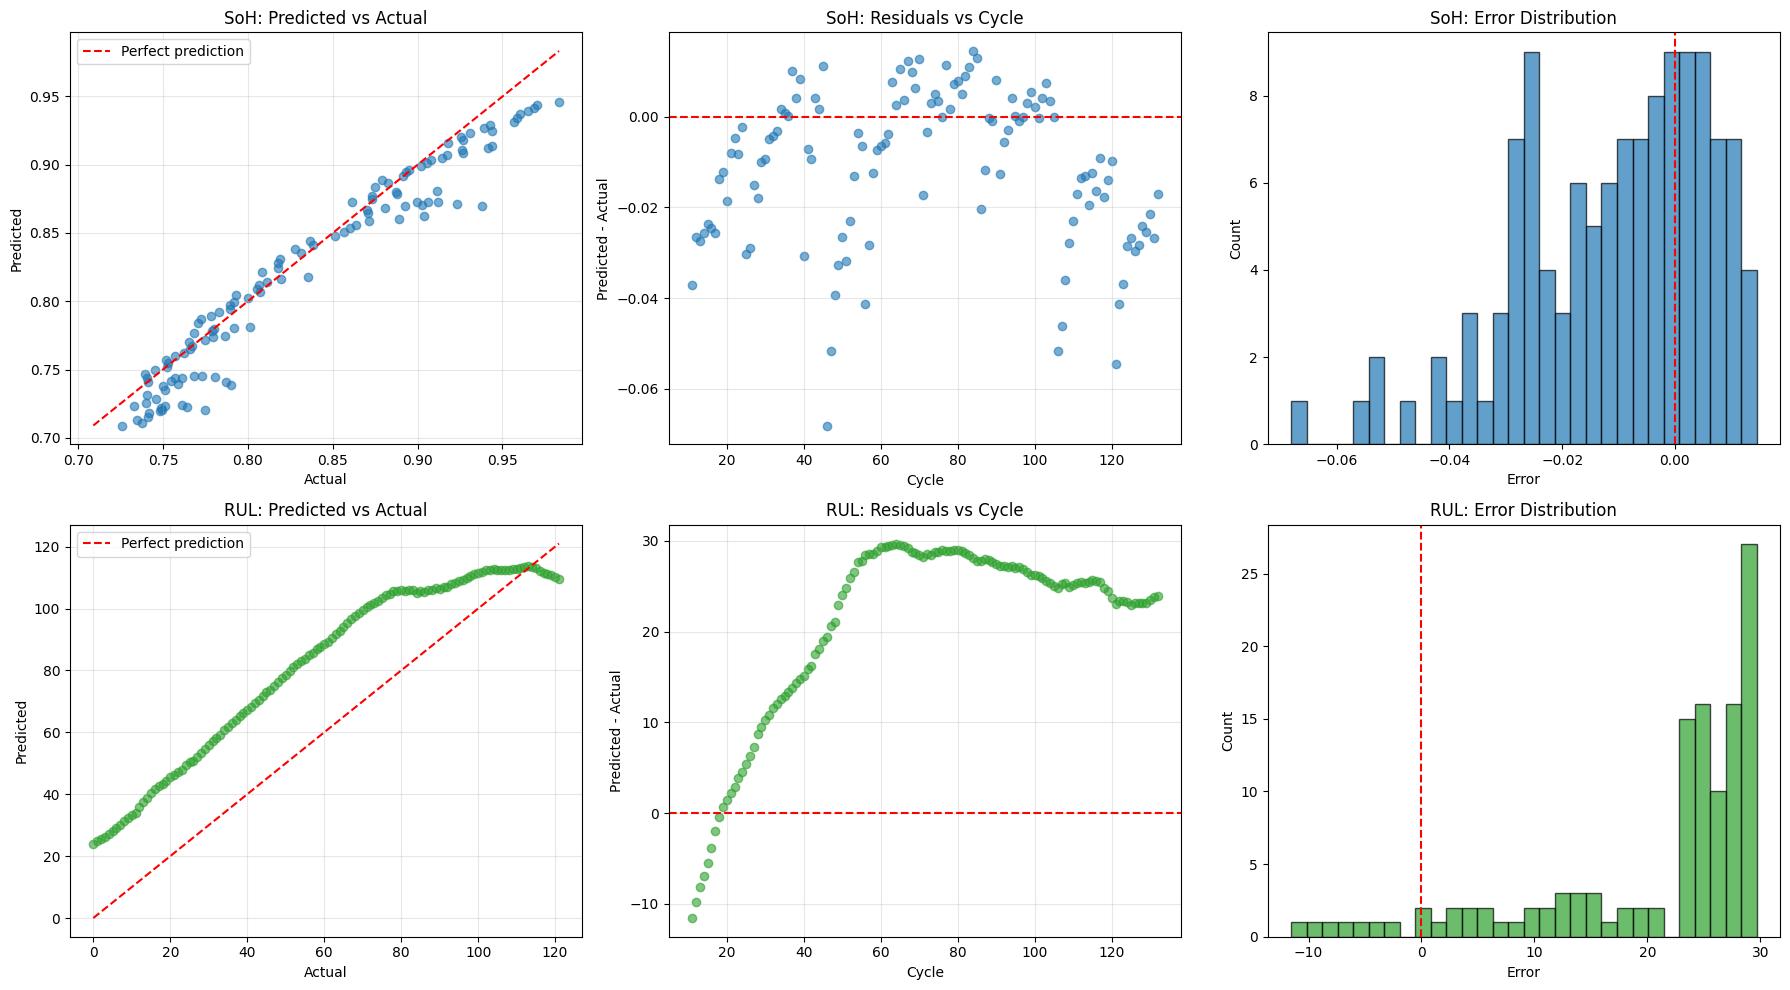

In [ ]:
# ------------------------------------------------------------
# 4. Diagnostic plots: scatter, residuals, error histogram
# ------------------------------------------------------------
soh_res = y_hat_soh - y_true_soh
rul_res = y_hat_rul - y_true_rul

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, (name, yt, yp, res, c) in enumerate([
        ('SoH', y_true_soh, y_hat_soh, soh_res, 'tab:blue'),
        ('RUL', y_true_rul, y_hat_rul, rul_res, 'tab:green')]):
    ax = axes[row, 0]
    ax.scatter(yt, yp, alpha=0.6, color=c)
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, 'r--', label='Perfect prediction')
    ax.set_title(f'{name}: Predicted vs Actual')
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted'); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[row, 1]
    ax.scatter(test_cycles, res, alpha=0.6, color=c)
    ax.axhline(0, color='r', linestyle='--')
    ax.set_title(f'{name}: Residuals vs Cycle')
    ax.set_xlabel('Cycle'); ax.set_ylabel('Predicted - Actual'); ax.grid(alpha=0.3)

    ax = axes[row, 2]
    ax.hist(res, bins=30, color=c, alpha=0.7, edgecolor='k')
    ax.axvline(0, color='r', linestyle='--')
    ax.set_title(f'{name}: Error Distribution')
    ax.set_xlabel('Error'); ax.set_ylabel('Count')
plt.tight_layout(); plt.show()

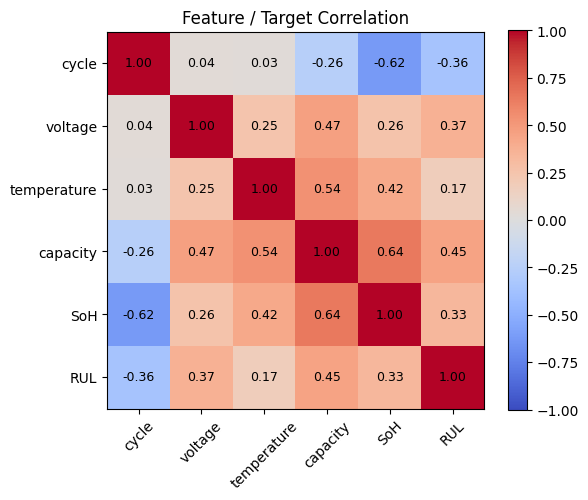

In [ ]:
# ------------------------------------------------------------
# 5. Correlation heatmap (raw df, unscaled)
# ------------------------------------------------------------
corr = df[features + ['SoH', 'RUL']].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
plt.colorbar(im); ax.set_title('Feature / Target Correlation'); plt.tight_layout(); plt.show()

In [ ]:
# ------------------------------------------------------------
# 6. Error vs life-stage
# ------------------------------------------------------------
stage = pd.cut(test_cycles / test_cycles.max(), bins=[0, 0.33, 0.66, 1.0],
               labels=['Early', 'Mid', 'Late'], include_lowest=True)
stage_df = pd.DataFrame({'stage': stage, 'SoH_AE': np.abs(soh_res), 'RUL_AE': np.abs(rul_res)})
print("\n=== MAE by life stage ===")
print(stage_df.groupby('stage', observed=True).mean().round(4))


=== MAE by life stage ===
       SoH_AE   RUL_AE
stage                 
Early  0.0139   8.8586
Mid    0.0142  27.2357
Late   0.0167  25.2477


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Dropout, LSTM, Dense
from tensorflow.keras.models import Model
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error


# ---------------------------------------------------------------
# Sequence builder (always returns proper 3-D float32 arrays)
# ---------------------------------------------------------------
def create_sequences_per_battery(df_part, feats, soh_col, rul_col, window):
    X, ys, yr, ids = [], [], [], []
    for bid, g in df_part.groupby('battery_id'):
        g = g.sort_values('cycle')
        vals = g[feats].to_numpy(dtype='float32')
        soh = g[soh_col].to_numpy(dtype='float32')
        rul = g[rul_col].to_numpy(dtype='float32')
        if len(g) <= window:
            continue                                   # battery too short
        for i in range(window, len(g)):
            X.append(vals[i - window:i])               # (window, n_feats)
            ys.append(soh[i])
            yr.append(rul[i])
            ids.append(bid)

    n_feats = len(feats)
    if len(X) == 0:                                    # keep 3-D even if empty
        return (np.empty((0, window, n_feats), dtype='float32'),
                np.empty((0,), dtype='float32'),
                np.empty((0,), dtype='float32'), [])

    return (np.stack(X).astype('float32'),
            np.asarray(ys, dtype='float32'),
            np.asarray(yr, dtype='float32'), ids)


# ---------------------------------------------------------------
# Model
# ---------------------------------------------------------------
def build_model(n_feats):
    inp = Input(shape=(WINDOW_SIZE, n_feats))
    x = Conv1D(64, 3, activation='relu', padding='same')(inp)
    x = MaxPooling1D(2)(x)
    x = Dropout(0.2)(x)
    x = LSTM(50, activation='tanh')(x)
    x = Dropout(0.2)(x)
    x = Dense(32, activation='relu')(x)
    soh_out = Dense(1, name='soh_output')(x)
    rul_out = Dense(1, name='rul_output')(x)
    m = Model(inp, [soh_out, rul_out])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss={'soh_output': 'mse', 'rul_output': 'huber'},
              metrics={'soh_output': ['mae'], 'rul_output': ['mae']})
    return m


# ---------------------------------------------------------------
# One experiment
# ---------------------------------------------------------------
def run_experiment(train_ids, val_id, test_id, feats, seed=42, verbose_shapes=False):
    tf.keras.utils.set_random_seed(seed)
    feats = list(feats)
    d = df.sort_values(['battery_id', 'cycle']).copy()

    active_train_ids = list(train_ids) if len(train_ids) > 0 else [val_id]

    fit_df = d[d['battery_id'].isin(active_train_ids + [val_id])].copy()
    te_df = d[d['battery_id'] == test_id].copy()

    f_sc, s_sc, r_sc = MinMaxScaler(), MinMaxScaler(), MinMaxScaler()
    f_sc.fit(fit_df[feats])
    s_sc.fit(fit_df[['SoH']])
    r_sc.fit(fit_df[['RUL']])

    for part in (fit_df, te_df):
        part[feats] = f_sc.transform(part[feats])
        part['SoH_s'] = s_sc.transform(part[['SoH']]).ravel()
        part['RUL_s'] = r_sc.transform(part[['RUL']]).ravel()

    tr_part = fit_df[fit_df['battery_id'].isin(active_train_ids)]
    va_part = fit_df[fit_df['battery_id'] == val_id]

    Xa, sa, ra, _ = create_sequences_per_battery(tr_part, feats, 'SoH_s', 'RUL_s', WINDOW_SIZE)
    Xv, sv, rv, _ = create_sequences_per_battery(va_part, feats, 'SoH_s', 'RUL_s', WINDOW_SIZE)
    Xt, st, rt, _ = create_sequences_per_battery(te_df, feats, 'SoH_s', 'RUL_s', WINDOW_SIZE)

    # Shape check (prints once if verbose_shapes=True)
    for name, arr in [('train', Xa), ('val', Xv), ('test', Xt)]:
        if verbose_shapes:
            print(name, arr.shape, arr.dtype)
        if arr.ndim != 3 or len(arr) == 0:
            raise ValueError(f"{name} sequences have bad shape: {arr.shape}")

    m = build_model(len(feats))

    es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                          restore_best_weights=True)
    m.fit(Xa, {'soh_output': sa, 'rul_output': ra},
          validation_data=(Xv, {'soh_output': sv, 'rul_output': rv}),
          epochs=100, batch_size=32, callbacks=[es], verbose=0)

    p = m.predict(Xt, verbose=0)
    ps = s_sc.inverse_transform(p[0].reshape(-1, 1)).ravel()
    pr = r_sc.inverse_transform(p[1].reshape(-1, 1)).ravel()

    soh_mae = mean_absolute_error(te_df['SoH'].iloc[WINDOW_SIZE:], ps)
    rul_mae = mean_absolute_error(te_df['RUL'].iloc[WINDOW_SIZE:], pr)

    return {'seed': seed, 'soh_mae': soh_mae, 'rul_mae': rul_mae}


# ---------------------------------------------------------------
# Seed variance on B0018
# ---------------------------------------------------------------
all_ids = sorted(df['battery_id'].unique())
counts = df.groupby('battery_id')['cycle'].count()

# Only batteries long enough to make windows
usable = [b for b in all_ids if b != 'B0018' and counts[b] > WINDOW_SIZE + 5]
dropped = [b for b in all_ids if b != 'B0018' and b not in usable]
if dropped:
    print("Skipping too-short batteries:", dropped, counts[dropped].to_dict())

if len(usable) > 1:
    t_ids = usable[:-1]
    v_id = usable[-1]
else:
    raise ValueError(f"Need at least 2 usable batteries besides B0018, got {usable}")
seed_rows = []
for s in range(N_SEEDS):
    res = run_experiment(t_ids, v_id, 'B0018', features, seed=s, verbose_shapes=(s == 0))
    seed_rows.append(res)

seed_df = pd.DataFrame(seed_rows)
print(f"\n=== Seed variance on B0018 ({N_SEEDS} seeds) ===")
print(seed_df.round(4).to_string(index=False))
print(seed_df[['soh_mae', 'rul_mae']].agg(['mean', 'std']).round(4))

Skipping too-short batteries: ['B0025', 'B0027', 'B0033', 'B0034', 'B0036', 'B0038', 'B0039', 'B0040', 'B0049', 'B0050', 'B0051', 'B0052', 'B0054', 'B0055', 'B0056'] {'B0025': 5, 'B0027': 14, 'B0033': 3, 'B0034': 1, 'B0036': 1, 'B0038': 1, 'B0039': 11, 'B0040': 2, 'B0049': 8, 'B0050': 2, 'B0051': 1, 'B0052': 1, 'B0054': 1, 'B0055': 1, 'B0056': 1}
train (1015, 10, 4) float32
val (35, 10, 4) float32
test (122, 10, 4) float32



=== Seed variance on B0018 (3 seeds) ===
 seed  soh_mae  rul_mae
    0   0.0150  20.8506
    1   0.0124  12.9853
    2   0.0132  15.1496
      soh_mae  rul_mae
mean   0.0135  16.3285
std    0.0014   4.0630


In [ ]:
# ------------------------------------------------------------
# Pick batteries that have enough cycles to make windows
# ------------------------------------------------------------
counts = df.groupby('battery_id')['cycle'].count()
all_ids = sorted(df['battery_id'].unique())
usable = [b for b in all_ids if counts[b] > WINDOW_SIZE + 5]
print("Usable:", usable, "| Too short (training only):", [b for b in all_ids if b not in usable])

# ------------------------------------------------------------
# 8. Leave-One-Battery-Out CV
# ------------------------------------------------------------
logo_rows = []
for b in usable:
    pool = [x for x in usable if x != b]
    vb = pool[-1]                                        # validation battery
    tr = [x for x in all_ids if x not in (b, vb)]        # short ones stay in training
    r = run_experiment(tr, vb, b, features, seed=42)
    r['Held-out battery'] = b
    logo_rows.append(r)

logo = pd.DataFrame(logo_rows)[['Held-out battery', 'SoH_MAE', 'SoH_R2', 'RUL_MAE', 'RUL_R2']]
print("\n=== Leave-One-Battery-Out CV (CNN-LSTM) ===")
print(logo.round(4).to_string(index=False))
print("\nMean ± Std:")
print(logo.drop(columns='Held-out battery').agg(['mean', 'std']).round(4))

# ------------------------------------------------------------
# 9. Ablation (leakage check) on B0018
# ------------------------------------------------------------
pool_b = [x for x in usable if x != 'B0018']
v_ab = pool_b[-1]
t_ab = [x for x in all_ids if x not in ('B0018', v_ab)]

abl_rows = []
for feats in [features,
              ['cycle', 'voltage', 'temperature'],      # without capacity
              ['voltage', 'temperature', 'capacity'],   # without cycle
              ['voltage', 'temperature']]:              # only sensor features
    r = run_experiment(t_ab, v_ab, 'B0018', feats, seed=42)
    r['Features'] = ', '.join(feats)
    abl_rows.append(r)

print("\n=== Ablation study (CNN-LSTM) ===")
print(pd.DataFrame(abl_rows)[['Features', 'SoH_MAE', 'SoH_R2', 'RUL_MAE', 'RUL_R2']]
      .round(4).to_string(index=False))

Usable: ['B0005', 'B0006', 'B0007', 'B0018', 'B0026', 'B0028', 'B0029', 'B0030', 'B0031', 'B0032', 'B0041', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0047', 'B0048', 'B0053'] | Too short (training only): ['B0025', 'B0027', 'B0033', 'B0034', 'B0036', 'B0038', 'B0039', 'B0040', 'B0049', 'B0050', 'B0051', 'B0052', 'B0054', 'B0055', 'B0056']


KeyError: "['SoH_MAE', 'SoH_R2', 'RUL_MAE', 'RUL_R2'] not in index"

In [ ]:
print(df.groupby('battery_id')['cycle'].count().sort_index())

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Dropout, LSTM, Dense
from tensorflow.keras.models import Model
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# NOTE: needs df, features, WINDOW_SIZE, N_SEEDS to be defined in earlier cells.

TEST_BATTERY = 'B0018'


# ---------------------------------------------------------------
# Sequence builder (always returns 3-D float32 arrays)
# ---------------------------------------------------------------
def create_sequences_per_battery(df_part, feats, soh_col, rul_col, window):
    X, ys, yr, ids = [], [], [], []
    for bid, g in df_part.groupby('battery_id'):
        g = g.sort_values('cycle')
        vals = g[feats].to_numpy(dtype='float32')
        soh = g[soh_col].to_numpy(dtype='float32')
        rul = g[rul_col].to_numpy(dtype='float32')
        if len(g) <= window:
            continue
        for i in range(window, len(g)):
            X.append(vals[i - window:i])
            ys.append(soh[i])
            yr.append(rul[i])
            ids.append(bid)

    if len(X) == 0:
        return (np.empty((0, window, len(feats)), dtype='float32'),
                np.empty((0,), dtype='float32'),
                np.empty((0,), dtype='float32'), [])

    return (np.stack(X).astype('float32'),
            np.asarray(ys, dtype='float32'),
            np.asarray(yr, dtype='float32'), ids)


# ---------------------------------------------------------------
# Model
# ---------------------------------------------------------------
def build_model(n_feats):
    inp = Input(shape=(WINDOW_SIZE, n_feats))
    x = Conv1D(64, 3, activation='relu', padding='same')(inp)
    x = MaxPooling1D(2)(x)
    x = Dropout(0.2)(x)
    x = LSTM(50, activation='tanh')(x)
    x = Dropout(0.2)(x)
    x = Dense(32, activation='relu')(x)
    soh_out = Dense(1, name='soh_output')(x)
    rul_out = Dense(1, name='rul_output')(x)
    m = Model(inp, [soh_out, rul_out])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss={'soh_output': 'mse', 'rul_output': 'huber'},
              metrics={'soh_output': ['mae'], 'rul_output': ['mae']})
    return m


# ---------------------------------------------------------------
# One experiment (train -> validate -> test on one battery)
# ---------------------------------------------------------------
def run_experiment(train_ids, val_id, test_id, feats, seed=42, verbose_shapes=False):
    tf.keras.utils.set_random_seed(seed)
    feats = list(feats)
    d = df.sort_values(['battery_id', 'cycle']).copy()

    active_train_ids = list(train_ids) if len(train_ids) > 0 else [val_id]

    fit_df = d[d['battery_id'].isin(active_train_ids + [val_id])].copy()
    te_df = d[d['battery_id'] == test_id].copy()

    f_sc, s_sc, r_sc = MinMaxScaler(), MinMaxScaler(), MinMaxScaler()
    f_sc.fit(fit_df[feats])
    s_sc.fit(fit_df[['SoH']])
    r_sc.fit(fit_df[['RUL']])

    for part in (fit_df, te_df):
        part[feats] = f_sc.transform(part[feats])
        part['SoH_s'] = s_sc.transform(part[['SoH']]).ravel()
        part['RUL_s'] = r_sc.transform(part[['RUL']]).ravel()

    tr_part = fit_df[fit_df['battery_id'].isin(active_train_ids)]
    va_part = fit_df[fit_df['battery_id'] == val_id]

    Xa, sa, ra, _ = create_sequences_per_battery(tr_part, feats, 'SoH_s', 'RUL_s', WINDOW_SIZE)
    Xv, sv, rv, _ = create_sequences_per_battery(va_part, feats, 'SoH_s', 'RUL_s', WINDOW_SIZE)
    Xt, st, rt, _ = create_sequences_per_battery(te_df, feats, 'SoH_s', 'RUL_s', WINDOW_SIZE)

    for name, arr in [('train', Xa), ('val', Xv), ('test', Xt)]:
        if verbose_shapes:
            print(name, arr.shape, arr.dtype)
        if arr.ndim != 3 or len(arr) == 0:
            raise ValueError(f"{name} sequences have bad shape: {arr.shape} "
                             f"(train={active_train_ids}, val={val_id}, test={test_id})")

    m = build_model(len(feats))
    es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                          restore_best_weights=True)
    m.fit(Xa, {'soh_output': sa, 'rul_output': ra},
          validation_data=(Xv, {'soh_output': sv, 'rul_output': rv}),
          epochs=100, batch_size=32, callbacks=[es], verbose=0)

    p = m.predict(Xt, verbose=0)
    ps = s_sc.inverse_transform(p[0].reshape(-1, 1)).ravel()
    pr = r_sc.inverse_transform(p[1].reshape(-1, 1)).ravel()

    y_soh = te_df['SoH'].iloc[WINDOW_SIZE:].to_numpy()
    y_rul = te_df['RUL'].iloc[WINDOW_SIZE:].to_numpy()

    soh_mae = mean_absolute_error(y_soh, ps)
    rul_mae = mean_absolute_error(y_rul, pr)

    return {'seed': seed,
            'soh_mae': soh_mae, 'rul_mae': rul_mae,
            'SoH_MAE': soh_mae,
            'SoH_RMSE': float(np.sqrt(mean_squared_error(y_soh, ps))),
            'SoH_R2': r2_score(y_soh, ps),
            'RUL_MAE': rul_mae,
            'RUL_RMSE': float(np.sqrt(mean_squared_error(y_rul, pr))),
            'RUL_R2': r2_score(y_rul, pr)}


# ---------------------------------------------------------------
# Choose usable batteries (enough cycles to make windows)
# ---------------------------------------------------------------
counts = df.groupby('battery_id')['cycle'].count()
all_ids = sorted(df['battery_id'].unique())
usable = [b for b in all_ids if counts[b] > WINDOW_SIZE + 5]
short = [b for b in all_ids if b not in usable]
print("Usable batteries:", usable)
print("Too short (used for training only):", short)

if TEST_BATTERY not in usable:
    raise ValueError(f"{TEST_BATTERY} is too short to test on.")

# Default split for B0018 experiments
pool_main = [b for b in usable if b != TEST_BATTERY]
if len(pool_main) < 2:
    raise ValueError(f"Need at least 2 usable batteries besides {TEST_BATTERY}, got {pool_main}")
v_id = pool_main[-1]
t_ids = [b for b in all_ids if b not in (TEST_BATTERY, v_id)]
print(f"Train: {t_ids} | Val: {v_id} | Test: {TEST_BATTERY}")


# ---------------------------------------------------------------
# 7. Seed variance on B0018
# ---------------------------------------------------------------
seed_rows = []
for s in range(N_SEEDS):
    seed_rows.append(run_experiment(t_ids, v_id, TEST_BATTERY, features,
                                    seed=s, verbose_shapes=(s == 0)))

seed_df = pd.DataFrame(seed_rows)
print(f"\n=== Seed variance on {TEST_BATTERY} ({N_SEEDS} seeds) ===")
print(seed_df[['seed', 'soh_mae', 'rul_mae']].round(4).to_string(index=False))
print(seed_df[['soh_mae', 'rul_mae']].agg(['mean', 'std']).round(4))


# ---------------------------------------------------------------
# 8. Leave-One-Battery-Out CV
# ---------------------------------------------------------------
logo_rows = []
for b in usable:
    pool = [x for x in usable if x != b]
    vb = pool[-1]
    tr = [x for x in all_ids if x not in (b, vb)]
    r = run_experiment(tr, vb, b, features, seed=42)
    r['Held-out battery'] = b
    logo_rows.append(r)

logo = pd.DataFrame(logo_rows)[['Held-out battery', 'SoH_MAE', 'SoH_RMSE', 'SoH_R2',
                                'RUL_MAE', 'RUL_RMSE', 'RUL_R2']]
print("\n=== Leave-One-Battery-Out CV (CNN-LSTM) ===")
print(logo.round(4).to_string(index=False))
print("\nMean ± Std:")
print(logo.drop(columns='Held-out battery').agg(['mean', 'std']).round(4))


# ---------------------------------------------------------------
# 9. Ablation (leakage check) on B0018
# ---------------------------------------------------------------
abl_rows = []
for feats in [list(features),
              ['cycle', 'voltage', 'temperature'],      # without capacity
              ['voltage', 'temperature', 'capacity'],   # without cycle
              ['voltage', 'temperature']]:              # only sensor features
    r = run_experiment(t_ids, v_id, TEST_BATTERY, feats, seed=42)
    r['Features'] = ', '.join(feats)
    abl_rows.append(r)

print("\n=== Ablation study (CNN-LSTM) ===")
print(pd.DataFrame(abl_rows)[['Features', 'SoH_MAE', 'SoH_R2', 'RUL_MAE', 'RUL_R2']]
      .round(4).to_string(index=False))

Usable batteries: ['B0005', 'B0006', 'B0007', 'B0018', 'B0026', 'B0028', 'B0029', 'B0030', 'B0031', 'B0032', 'B0041', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0047', 'B0048', 'B0053']
Too short (used for training only): ['B0025', 'B0027', 'B0033', 'B0034', 'B0036', 'B0038', 'B0039', 'B0040', 'B0049', 'B0050', 'B0051', 'B0052', 'B0054', 'B0055', 'B0056']
Train: ['B0005', 'B0006', 'B0007', 'B0025', 'B0026', 'B0027', 'B0028', 'B0029', 'B0030', 'B0031', 'B0032', 'B0033', 'B0034', 'B0036', 'B0038', 'B0039', 'B0040', 'B0041', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0047', 'B0048', 'B0049', 'B0050', 'B0051', 'B0052', 'B0054', 'B0055', 'B0056'] | Val: B0053 | Test: B0018
train (1020, 10, 4) float32
val (35, 10, 4) float32
test (122, 10, 4) float32

=== Seed variance on B0018 (3 seeds) ===
 seed  soh_mae  rul_mae
    0   0.0137  32.0481
    1   0.0159  15.8643
    2   0.0160  28.8004
      soh_mae  rul_mae
mean   0.0152  25.5709
std    0.0013   8.5616

=== Leave-One-Battery-Out CV 